In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt

df = pd.read_csv('/Users/mirabelleding/Downloads/cars.csv')

In [ ]:
cars = df.drop(['doors','lug_boot', 'persons'], axis=1)
cars = cars.rename(columns={
    'class': 'evaluation',
    'buying':'price',
})

# assign numeric value to each of the ordinal categorical feature values
price_ranges = {
    'low': (10000, 30000),
    'med': (30001, 50000),
    'high': (50001, 100000),
    'vhigh': (100001, 150000)
}

maint_ranges = {
    'low': (500, 1500),
    'med': (1501, 3000),
    'high': (3001, 5000),
    'vhigh': (5001, 7500)
}

# Assign random values within each range
cars['price'] = cars['price'].map(lambda x: np.random.randint(*price_ranges.get(x, (5000, 10000))))
cars['maint'] = cars['maint'].map(lambda x: np.random.randint(*maint_ranges.get(x, (500, 1500))))

safety_new = {'low':0, 'med': 1, 'high':1 }
evaluation_new = {
    'unacc': 0,
    'acc': 1,
    'vgood': 3,
    'good': 2,
}

cars['safety'].replace(safety_new, inplace=True)
cars['evaluation'].replace(evaluation_new, inplace=True)

cars.head()

,price,maint,safety,evaluation
0,119066,5124,0,0
1,117925,5422,1,0
2,122557,6509,1,0
3,126963,6598,0,0
4,128296,5768,1,0


In [ ]:
# split into training and testing sets
X = cars.drop('evaluation', axis=1)  # input variables
y = cars['evaluation']  # output variable

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Use GridSearchCV to find out the optimal hyperparameters
param_grid = {
    'max_depth': [3, 5, 7, 10],
    'min_samples_split': [2, 5, 10, 20]
}

clf = DecisionTreeClassifier(random_state=42)
grid_search = GridSearchCV(estimator=clf, param_grid=param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

print("Best max_depth:", grid_search.best_params_['max_depth'],
    "\nBest min_samples_split:", grid_search.best_params_['min_samples_split'],
    "\nBest cross-validation score:", grid_search.best_score_)

Best max_depth: 3 
Best min_samples_split: 2 
Best cross-validation score: 0.7098336210955893


In [ ]:
# set hyperparameters as identified above
clf = DecisionTreeClassifier(max_depth=3, min_samples_split=2, random_state=42)
clf.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

## Model Accuracy Evaluation

In [ ]:
y_pred = clf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy Score:", accuracy)

# Detailed classification report
print(classification_report(y_test, y_pred, zero_division=1))

Accuracy Score: 0.6647398843930635
              precision    recall  f1-score   support

           0       0.78      0.73      0.75       235
           1       0.46      0.70      0.56        83
           2       1.00      0.00      0.00        11
           3       1.00      0.00      0.00        17

    accuracy                           0.66       346
   macro avg       0.81      0.36      0.33       346
weighted avg       0.72      0.66      0.65       346



## Decision Tree Plot

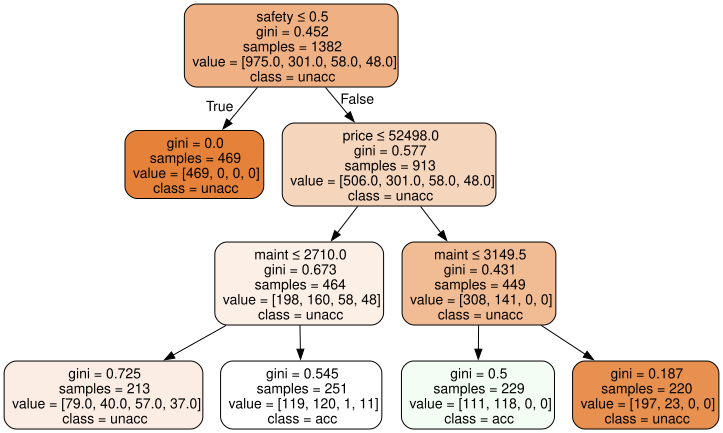

In [ ]:
from sklearn.tree import export_graphviz
from graphviz import Source
import graphviz

dot_data = export_graphviz(clf, out_file=None,
                           feature_names=X.columns,
                           class_names=['unacc', 'acc', 'good','vgood'],
                           rounded=True,
                           filled=True,
                           special_characters=True)

source = Source(dot_data)

with open("tree.dot", "w") as f:
    f.write(dot_data)

source

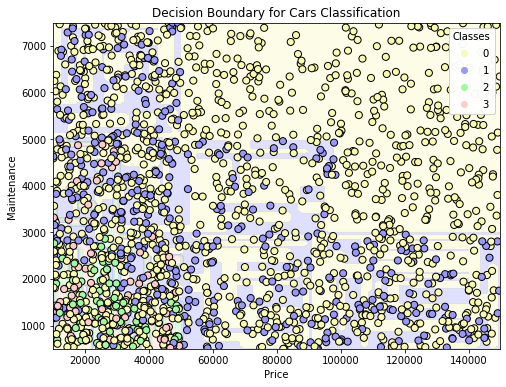

In [ ]:
from sklearn.preprocessing import OneHotEncoder
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt

encoder = OneHotEncoder()
encoded_safety = encoder.fit_transform(cars[['safety']]).toarray()

# Create a new DataFrame with encoded features
encoded_df = pd.DataFrame(encoded_safety, columns=encoder.get_feature_names_out(['safety']))
X = pd.concat([cars[['price', 'maint']], encoded_df], axis=1)
y = cars['evaluation']

# Train the decision tree classifier
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X, y)

# Function to plot decision boundary
def plot_decision_boundary(clf, X, y, axes=[X.iloc[:, 0].min(), X.iloc[:, 0].max(),
                                             X.iloc[:, 1].min(), X.iloc[:, 1].max()]):
    x1s = np.linspace(axes[0], axes[1], 100)
    x2s = np.linspace(axes[2], axes[3], 100)
    x1, x2 = np.meshgrid(x1s, x2s)

    # Create X_new as a DataFrame with the correct feature names
    X_new = pd.DataFrame(
        np.c_[x1.ravel(), x2.ravel(), np.zeros((x1.size, len(encoder.categories_[0])))],
        columns=X.columns
    )

    y_pred = clf.predict(X_new).reshape(x1.shape)

    custom_cmap = ListedColormap(['#fafab0', '#9898ff', '#a0faa0', '#ffcccb'])
    plt.contourf(x1, x2, y_pred, alpha=0.3, cmap=custom_cmap)
    scatter_plot = plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y, edgecolor='k', s=50, cmap=custom_cmap)

    plt.xlabel('Price')
    plt.ylabel('Maintenance')
    plt.title('Decision Boundary for Cars Classification')

    # Add a legend using the scatter plot object
    legend1 = plt.legend(*scatter_plot.legend_elements(), title="Classes")
    plt.gca().add_artist(legend1)

    plt.show()

plt.figure(figsize=(8, 6))
plot_decision_boundary(clf, X, y)

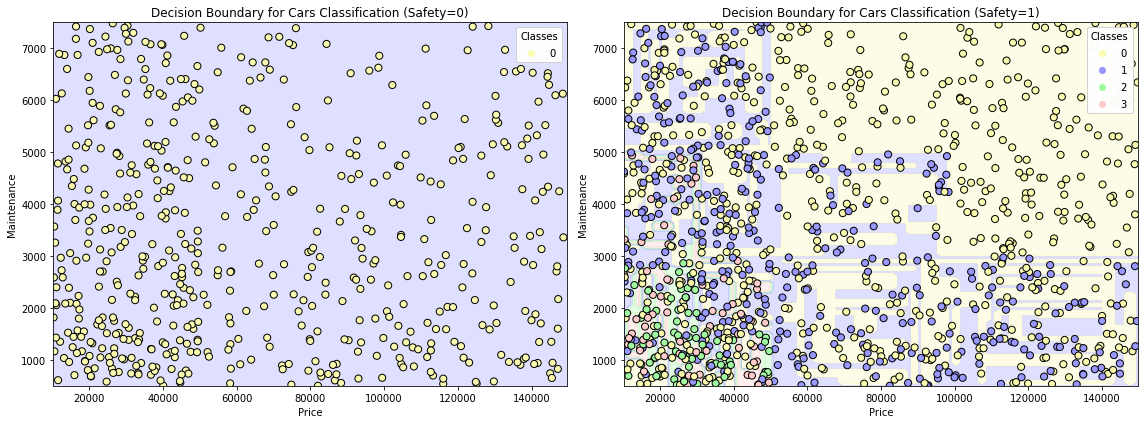

In [ ]:
def plot_decision_boundary(clf, X, y, safety, ax, axes=[None, None, None, None]):
    x1s = np.linspace(axes[0], axes[1], 100)
    x2s = np.linspace(axes[2], axes[3], 100)
    x1, x2 = np.meshgrid(x1s, x2s)

    if safety == 0:
        X_new = pd.DataFrame(
            np.c_[x1.ravel(), x2.ravel(), np.ones(x1.size), np.zeros(x1.size)],
            columns=['price', 'maint', 'safety_0', 'safety_1']
        )
    else:
        X_new = pd.DataFrame(
            np.c_[x1.ravel(), x2.ravel(), np.zeros(x1.size), np.ones(x1.size)],
            columns=['price', 'maint', 'safety_0', 'safety_1']
        )

    y_pred = clf.predict(X_new).reshape(x1.shape)

    custom_cmap = ListedColormap(['#fafab0', '#9898ff', '#a0faa0', '#ffcccb'])
    contour = ax.contourf(x1, x2, y_pred, alpha=0.3, cmap=custom_cmap)

    # segment the data for different safety rating
    if safety == 0:
        mask = X['safety_0'] == 1
    else:
        mask = X['safety_1'] == 1

    scatter_plot = ax.scatter(X[mask]['price'],
                              X[mask]['maint'],
                              c=y[mask],
                              edgecolor='k',
                              s=50,
                              cmap=custom_cmap)

    ax.set_xlabel('Price')
    ax.set_ylabel('Maintenance')
    ax.set_title(f'Decision Boundary for Cars Classification (Safety={safety})')

    legend1 = ax.legend(*scatter_plot.legend_elements(), title="Classes")
    ax.add_artist(legend1)

fig, axs = plt.subplots(1, 2, figsize=(16, 6))
axes = [X['price'].min(), X['price'].max(), X['maint'].min(), X['maint'].max()]

plot_decision_boundary(clf, X, y, safety=0, ax=axs[0], axes=axes)
plot_decision_boundary(clf, X, y, safety=1, ax=axs[1], axes=axes)

plt.tight_layout()
plt.show()

## Predicting Evaluation Classes and Probabilities

In [ ]:
# INPUT 1
input_data = {
    'price': [70000],
    'maint': [3000],
    'safety_0': [0],
    'safety_1':[1]
}

input_df = pd.DataFrame(input_data)


predictions = clf.predict(input_df)
predicted_probabilities = clf.predict_proba(input_df)

predicted_class = predictions[0]
class_names = ['unacc', 'acc', 'vgood', 'good']
print(f"The predicted class is: {class_names[predicted_class]}")
print("Predicted probabilities for each class:")
for class_name, probability in zip(class_names, predicted_probabilities[0]):
    print(f"{class_name}: {probability:.2f}")

The predicted class is: unacc
Predicted probabilities for each class:
unacc: 1.00
acc: 0.00
vgood: 0.00
good: 0.00


In [ ]:
# INPUT 2
input_data2 = {
    'price': [10000],
    'maint': [4000],
    'safety_0': [0],
    'safety_1':[1]
}

input_df2 = pd.DataFrame(input_data2)


predictions = clf.predict(input_df2)
predicted_probabilities = clf.predict_proba(input_df2)

predicted_class = predictions[0]
class_names = ['unacc', 'acc', 'vgood', 'good']
print(f"The predicted class is: {class_names[predicted_class]}")
print("Predicted probabilities for each class:")
for class_name, probability in zip(class_names, predicted_probabilities[0]):
    print(f"{class_name}: {probability:.2f}")

The predicted class is: unacc
Predicted probabilities for each class:
unacc: 1.00
acc: 0.00
vgood: 0.00
good: 0.00


In [ ]:
# INPUT 3
input_data3 = {
    'price': [100000],
    'maint': [1000],
    'safety_0': [1],
    'safety_1':[0]
}

input_df3 = pd.DataFrame(input_data3)


predictions = clf.predict(input_df3)
predicted_probabilities = clf.predict_proba(input_df3)

predicted_class = predictions[0]
class_names = ['unacc', 'acc', 'vgood', 'good']
print(f"The predicted class is: {class_names[predicted_class]}")
print("Predicted probabilities for each class:")
for class_name, probability in zip(class_names, predicted_probabilities[0]):
    print(f"{class_name}: {probability:.2f}")

The predicted class is: unacc
Predicted probabilities for each class:
unacc: 1.00
acc: 0.00
vgood: 0.00
good: 0.00


## Dataset Examination

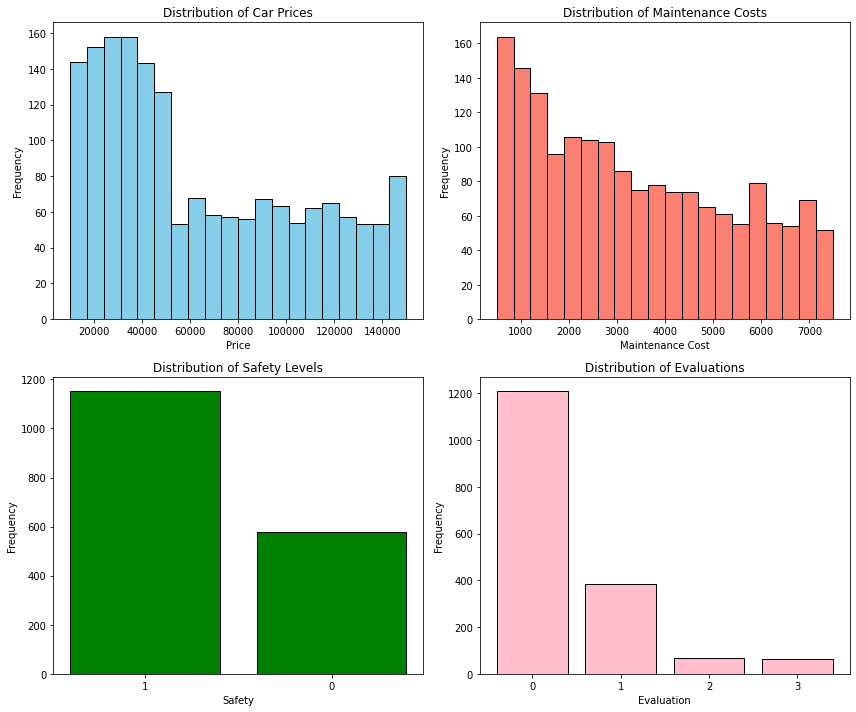

In [ ]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# Plot histogram for price
axs[0, 0].hist(cars['price'], bins=20, color='skyblue', edgecolor='black')
axs[0, 0].set_title('Distribution of Car Prices')
axs[0, 0].set_xlabel('Price')
axs[0, 0].set_ylabel('Frequency')

# Plot histogram for maintenance
axs[0, 1].hist(cars['maint'], bins=20, color='salmon', edgecolor='black')
axs[0, 1].set_title('Distribution of Maintenance Costs')
axs[0, 1].set_xlabel('Maintenance Cost')
axs[0, 1].set_ylabel('Frequency')

# Plot bar chart for safety
safety_counts = cars['safety'].value_counts()
axs[1, 0].bar(safety_counts.index.astype(str), safety_counts.values, color='green', edgecolor='black')  # Convert indices to string for better labeling
axs[1, 0].set_title('Distribution of Safety Levels')
axs[1, 0].set_xlabel('Safety')
axs[1, 0].set_ylabel('Frequency')

# Plot bar chart for evaluation
evaluation_counts = cars['evaluation'].value_counts()
axs[1, 1].bar(evaluation_counts.index.astype(str), evaluation_counts.values, color='pink', edgecolor='black')  # Convert indices to string for better labeling
axs[1, 1].set_title('Distribution of Evaluations')
axs[1, 1].set_xlabel('Evaluation')
axs[1, 1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

#### This dataset is extremely right skewed in the two numerical inputs of listing price and maintenance costs, and therefor may introduce bias toward majority range and impact the model's interpretation and accuracy

***
## Sensitivity to Traning Set Details

In [ ]:
# lowest 25% of car prices where evaluation is acceptable, good, or very good
lowest_25_percent_cars = cars[(cars['evaluation'].isin([0, 1, 2, 3])) &
                              (cars['price'] <= cars[cars['evaluation'].isin([1, 2, 3])]['price'].quantile(0.25))]

lowest_25_percent_cars

,price,maint,safety,evaluation
1296,19024,5542,0,0
1297,21585,6845,1,0
1299,22659,5547,0,0
1300,17800,5984,1,0
1303,17672,6980,1,0
...,...,...,...,...
1723,17887,788,1,2
1724,11785,1115,1,3
1725,19640,640,0,0
1726,18029,702,1,2


In [ ]:
# tweaked DataFrame excluding rows present in lowest_25_percent_cars
cars_tweaked = cars.merge(
    lowest_25_percent_cars[['price', 'maint', 'safety', 'evaluation']],
    on=['price', 'maint', 'safety', 'evaluation'],
    how='left',
    indicator=True
).query('_merge == "left_only"').drop('_merge', axis=1)

cars_tweaked

,price,maint,safety,evaluation
0,133008,5482,0,0
1,123824,6382,1,0
2,102191,5362,1,0
3,148058,6060,0,0
4,137460,5516,1,0
...,...,...,...,...
1701,24956,1245,0,0
1703,25007,598,1,0
1718,28810,1181,1,3
1719,27323,597,0,0


In [ ]:
X_tweaked = cars_tweaked.drop('evaluation', axis=1)
y_tweaked = cars_tweaked['evaluation']

X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(X_tweaked, y_tweaked, test_size=0.2, random_state=42)

param_grid = {
    'max_depth': [3, 5, 7, 10],
    'min_samples_split': [2, 5, 10, 20]
}

clf_tweaked = DecisionTreeClassifier(random_state=42)
grid_search = GridSearchCV(estimator=clf, param_grid=param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train_t, y_train_t)

print("Best max_depth:", grid_search.best_params_['max_depth'],
    "\nBest min_samples_split:", grid_search.best_params_['min_samples_split'],
    "\nBest cross-validation score:", grid_search.best_score_)

Best max_depth: 3 
Best min_samples_split: 2 
Best cross-validation score: 0.7278305896900843


In [ ]:
clf_tweaked = DecisionTreeClassifier(max_depth=3, min_samples_split=2, random_state=42)
clf_tweaked.fit(X_train_t, y_train_t)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [ ]:
y_pred_t = clf_tweaked.predict(X_test_t)

accuracy = accuracy_score(y_test_t, y_pred_t)
print("Accuracy Score:", accuracy)

# Detailed classification report
print(classification_report(y_test_t, y_pred_t, zero_division=1))

Accuracy Score: 0.7157894736842105
              precision    recall  f1-score   support

           0       0.80      0.83      0.82       217
           1       0.39      0.43      0.41        56
           2       1.00      0.00      0.00         6
           3       1.00      0.00      0.00         6

    accuracy                           0.72       285
   macro avg       0.80      0.31      0.31       285
weighted avg       0.73      0.72      0.70       285



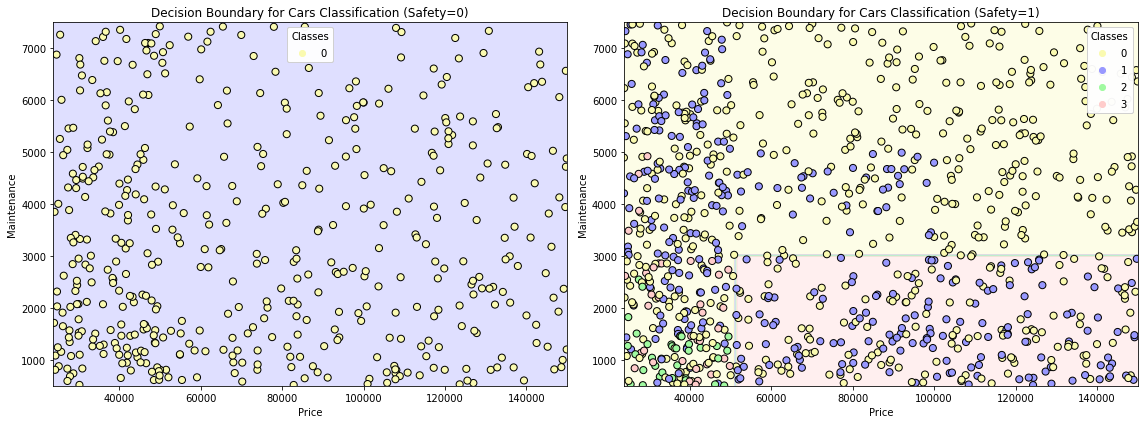

In [ ]:
def plot_decision_boundary(clf_tweaked, X_tweaked, y_tweaked, safety, ax, axes=[None, None, None, None]):
    x1s = np.linspace(axes[0], axes[1], 100)
    x2s = np.linspace(axes[2], axes[3], 100)
    x1, x2 = np.meshgrid(x1s, x2s)

    # Create a DataFrame with the relevant features and safety flag
    X_new = pd.DataFrame(np.c_[x1.ravel(), x2.ravel()], columns=['price', 'maint'])
    X_new['safety'] = safety  # Assign safety after creating the DataFrame

    # Predict the class for the new data points
    y_pred = clf_tweaked.predict(X_new).reshape(x1.shape)

    # Custom colormap for the plot
    custom_cmap = ListedColormap(['#fafab0', '#9898ff', '#a0faa0', '#ffcccb'])
    contour = ax.contourf(x1, x2, y_pred, alpha=0.3, cmap=custom_cmap)

    # Segment the data for different safety ratings
    mask = X_tweaked['safety'] == safety

    scatter_plot = ax.scatter(X_tweaked[mask]['price'],
                              X_tweaked[mask]['maint'],
                              c=y_tweaked[mask],
                              edgecolor='k',
                              s=50,
                              cmap=custom_cmap)

    ax.set_xlabel('Price')
    ax.set_ylabel('Maintenance')
    ax.set_title(f'Decision Boundary for Cars Classification (Safety={safety})')

    # Create a legend for the scatter plot
    legend1 = ax.legend(*scatter_plot.legend_elements(), title="Classes")
    ax.add_artist(legend1)

# Create subplots
fig, axs = plt.subplots(1, 2, figsize=(16, 6))

# Define the axes limits based on the data
axes = [X_tweaked['price'].min(), X_tweaked['price'].max(),
         X_tweaked['maint'].min(), X_tweaked['maint'].max()]

# Plot decision boundaries for safety levels 0 and 1
plot_decision_boundary(clf_tweaked, X_tweaked, y_tweaked, safety=0, ax=axs[0], axes=axes)
plot_decision_boundary(clf_tweaked, X_tweaked, y_tweaked, safety=1, ax=axs[1], axes=axes)

plt.tight_layout()
plt.show()

In [ ]:
# Prediction for the tweaked decision tree classifier
input_data = {
    'price': [70000],
    'maint': [3000],
    'safety': [1]
}

input_df = pd.DataFrame(input_data)


predictions = clf_tweaked.predict(input_df)
predicted_probabilities = clf_tweaked.predict_proba(input_df)

predicted_class = predictions[0]
class_names = ['unacc', 'acc', 'vgood', 'good']
print(f"The predicted class is: {class_names[predicted_class]}")
print("Predicted probabilities for each class:")
for class_name, probability in zip(class_names, predicted_probabilities[0]):
    print(f"{class_name}: {probability:.2f}")

The predicted class is: unacc
Predicted probabilities for each class:
unacc: 0.88
acc: 0.12
vgood: 0.00
good: 0.00


## Introducing Noise/Inconsistent Data

In [ ]:
cars.groupby(['safety','evaluation']).count()

price  maint
safety evaluation              
0      0             576    576
1      0             634    634
       1             384    384
       2              69     69
       3              65     65

#### Since low safety rating cars are classified as unacceptable (0), a noise introduction	in the final evaluation of cars with low safety input is implemented to test the model's robustness and avoid overfitting.

In [ ]:
cars_noise = cars.copy()

safety_0_indices = cars_noise[cars_noise['safety'] == 0].index

np.random.seed(42)
sample_size = int(0.10 * len(safety_0_indices)) # Select 10% of the data entries to add noise
selected_indices = np.random.choice(safety_0_indices, size=sample_size, replace=False)

# Randomly assign evaluation class of 1 or 2 to the selected low safety rating cars
cars_noise.loc[selected_indices, 'evaluation'] = np.random.choice([1, 2], size=sample_size)

cars_noise

,price,maint,safety,evaluation
0,119066,5124,0,0
1,117925,5422,1,0
2,122557,6509,1,0
3,126963,6598,0,0
4,128296,5768,1,0
...,...,...,...,...
1723,11403,1102,1,2
1724,19011,1289,1,3
1725,13292,1112,0,0
1726,19011,654,1,2


In [ ]:
cars_noise.groupby(['safety','evaluation']).count()

price  maint
safety evaluation              
0      0             519    519
       1              33     33
       2              24     24
1      0             634    634
       1             384    384
       2              69     69
       3              65     65

In [ ]:
X_noise = cars_noise.drop('evaluation', axis=1)
y_noise = cars_noise['evaluation']

X_train_n, X_test_n, y_train_n, y_test_n = train_test_split(X_noise, y_noise, test_size=0.2, random_state=42)

param_grid = {
    'max_depth': [3, 5, 7, 10],
    'min_samples_split': [2, 5, 10, 20]
}

clf_noise = DecisionTreeClassifier(random_state=42)
grid_search = GridSearchCV(estimator=clf, param_grid=param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train_n, y_train_n)

print("Best max_depth:", grid_search.best_params_['max_depth'],
    "\nBest min_samples_split:", grid_search.best_params_['min_samples_split'],
    "\nBest cross-validation score:", grid_search.best_score_)

Best max_depth: 10 
Best min_samples_split: 20 
Best cross-validation score: 0.6714775283838226


In [ ]:
clf_noise = DecisionTreeClassifier(max_depth=10, min_samples_split=20, random_state=42)
clf_noise.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=10, min_samples_split=20, random_state=42)

In [ ]:
y_pred = clf_noise.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy Score:", accuracy)

print(classification_report(y_test, y_pred, zero_division=1))

Accuracy Score: 0.6502890173410405
              precision    recall  f1-score   support

           0       0.74      0.80      0.77       235
           1       0.41      0.41      0.41        83
           2       0.33      0.09      0.14        11
           3       0.14      0.06      0.08        17

    accuracy                           0.65       346
   macro avg       0.41      0.34      0.35       346
weighted avg       0.62      0.65      0.63       346



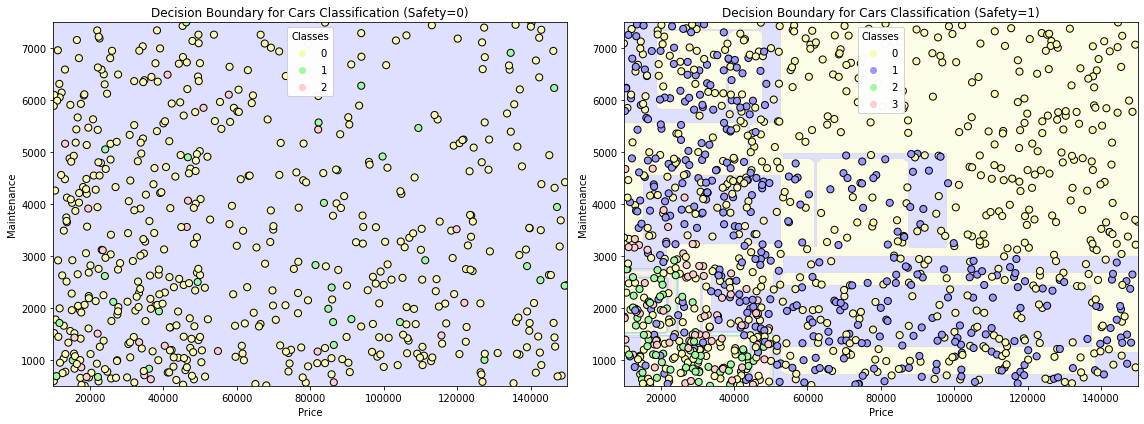

In [ ]:
def plot_decision_boundary(clf_noise, X_noise, y_noise, safety, ax, axes=[None, None, None, None]):
    x1s = np.linspace(axes[0], axes[1], 100)
    x2s = np.linspace(axes[2], axes[3], 100)
    x1, x2 = np.meshgrid(x1s, x2s)

    # Create a DataFrame with the relevant features and safety flag
    X_new = pd.DataFrame(np.c_[x1.ravel(), x2.ravel()], columns=['price', 'maint'])
    X_new['safety'] = safety  # Assign safety after creating the DataFrame

    # Predict the class for the new data points
    y_pred = clf_noise.predict(X_new).reshape(x1.shape)

    # Custom colormap for the plot
    custom_cmap = ListedColormap(['#fafab0', '#9898ff', '#a0faa0', '#ffcccb'])
    contour = ax.contourf(x1, x2, y_pred, alpha=0.3, cmap=custom_cmap)

    # Segment the data for different safety ratings
    mask = X_noise['safety'] == safety

    scatter_plot = ax.scatter(X_noise[mask]['price'],
                              X_noise[mask]['maint'],
                              c=y_noise[mask],
                              edgecolor='k',
                              s=50,
                              cmap=custom_cmap)

    ax.set_xlabel('Price')
    ax.set_ylabel('Maintenance')
    ax.set_title(f'Decision Boundary for Cars Classification (Safety={safety})')

    # Create a legend for the scatter plot
    legend1 = ax.legend(*scatter_plot.legend_elements(), title="Classes")
    ax.add_artist(legend1)

# Create subplots
fig, axs = plt.subplots(1, 2, figsize=(16, 6))

# Define the axes limits based on the data
axes = [X_noise['price'].min(), X_noise['price'].max(),
         X_noise['maint'].min(), X_noise['maint'].max()]

# Plot decision boundaries for safety levels 0 and 1
plot_decision_boundary(clf_noise, X_noise, y_noise, safety=0, ax=axs[0], axes=axes)
plot_decision_boundary(clf_noise, X_noise, y_noise, safety=1, ax=axs[1], axes=axes)

plt.tight_layout()
plt.show()

In [ ]:
# Prediction for the decision tree classifier with introduced noise
input_data = {
    'price': [70000],
    'maint': [3000],
    'safety': [1],
}

input_df = pd.DataFrame(input_data)


predictions = clf_noise.predict(input_df)
predicted_probabilities = clf_noise.predict_proba(input_df)

predicted_class = predictions[0]
class_names = ['unacc', 'acc', 'vgood', 'good']
print(f"The predicted class is: {class_names[predicted_class]}")
print("Predicted probabilities for each class:")
for class_name, probability in zip(class_names, predicted_probabilities[0]):
    print(f"{class_name}: {probability:.2f}")

The predicted class is: unacc
Predicted probabilities for each class:
unacc: 0.67
acc: 0.33
vgood: 0.00
good: 0.00
